## Python 面向对象

### 面向对象三大特性

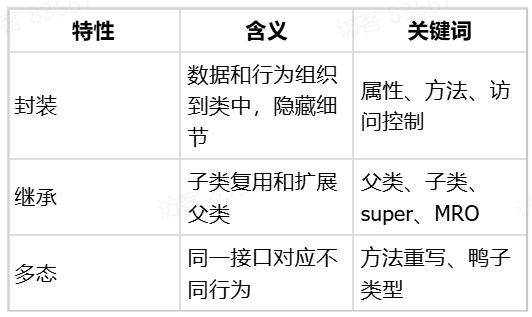

In [67]:
class Animal:
    species = "Animal"  # 类属性
    def __init__(self, name):
        self.name = name

    def speak(self):
        raise NotImplementedError("子类必须实现 speak 方法")

class Dog(Animal):
    def __init__(self, name, age):
        super().__init__(name) # 调用父类的init
        self.__age = age  # 私有属性

    def speak(self):
        return f"{self.name} says Woof!"

class Cat(Animal):
    def speak(self):
        return f"{self.name} says Meow!"

def animal_speak(animal):
    return animal.speak()

# 封装：Animal 封装了 name 和 speak 接口
# 继承：Dog 和 Cat 继承了 Animal
# 多态：
# - Dog 和 Cat 重写了 speak 方法，实现了多态
# - animal_speak 函数可以接受任何 Animal 的子类对象，并调用其 speak 方法（鸭子类型）

In [73]:
# 创建对象
d = Dog("Buddy", 3)
c = Cat("Kitty")
# 对象属性
print(d.name, d._Dog__age)  # Buddy 3
print(c.name)  # Kitty
# 对象方法
print(d.speak())
print(c.speak())

# 多态：鸭子类型
print(animal_speak(d))  # Buddy says Woof!
print(animal_speak(c))  # Kitty says Meow!

# 类属性和对象属性的区别
# - 类属性，所有对象共享
# - 对象属性，每个对象独有
print(Animal.species)
print(Cat.species)
print(c.species)

Buddy 3
Kitty
Buddy says Woof!
Kitty says Meow!
Buddy says Woof!
Kitty says Meow!
Animal
Animal
Animal


Python 没有严格 private，通过 _name, __name 等命名约定来表达访问限制

Python 支持多继承，方法查找遵循MRO

Python 多态主要通过鸭子类型体现，不一定要求共同父类

In [74]:
# issubclass(A, B) 判断 A 是否是 B 的子类
print(issubclass(Animal, object)) # 用 class 定义出来的类，默认继承 object
print(issubclass(Dog, Animal))
print(issubclass(Cat, Animal))

True
True
True


### init 是什么
- init 用于初始化对象的属性。当创建对象后，__init__ 方法会自动调用
- init 的作用：
    - 初始化对象属性
    - 检查构造函数参数
    - 设置对象初始状态
    - 建立对象依赖关系


init 不是构造函数，真正的构造函数是 new 方法，它负责创建对象并返回对象引用。init 方法在对象创建后被调用，用于初始化对象属性
```
u = User("Alice", 18)
大致流程：
1. User.__new__(User, "Alice", 18) 创建对象
2. User.__init__(u, "Alice", 18) 初始化对象属性
3. u = User("Alice", 18) 返回对象引用
```

### self 是什么
- 对象方法中的第一个参数，表示当前正在调用这个方法的对象本身
- 作用：访问对象属性和方法

self 和 cls 的区别:
- self：表示对象本身，指向当前实例
- cls：表示类本身，指向当前类

In [76]:
class Animal:
    count = 0  # 类属性
    def __init__(self, name):
        self.name = name  # 对象属性
        Animal.count += 1  # 类属性计数

    # 类方法
    @classmethod
    def get_count(cls):
        return cls.count

cat = Animal("Kitty")
print(Animal.get_count())  # 1
dog = Animal("Buddy")
print(Animal.get_count())  # 2

1
2


### @classmethod 和 @staticmethod 的区别（重点）
- @classmethod：类方法，第一个参数是 cls，表示类本身，可以访问类属性和方法
- @staticmethod：静态方法，没有默认参数，不自动接收类或实例的引用

静态方法适用场景：
- 逻辑上属于这个类
- 不需要访问对象属性
- 不需要访问类属性


类方法适用场景
- 需要访问或修改类属性
- 需要根据类来创建对象
- 作为替代构造函数
- 支持继承多态

⭐ 一句话记忆: self 传实例 / cls 传类 / 静态啥都不传

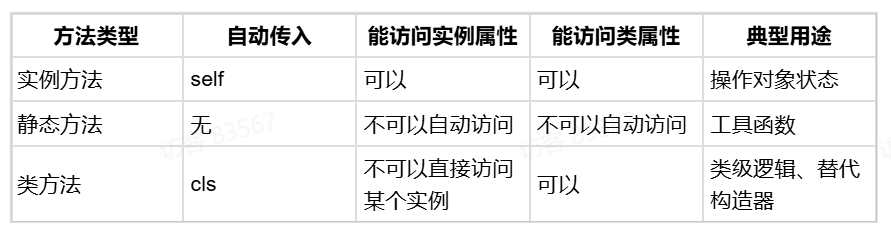

In [104]:
# =========================================================================
#  三种方法并存的类 —— 实例方法 / 类方法 / 静态方法 全覆盖
# =========================================================================
class Demo:
    version = "1.0"
    def instance_method(self):
        print("实例方法:", self)

    @classmethod
    def class_method(cls):
        print("类方法", cls)

    @staticmethod
    def static_method():
        print("静态方法")
        # print("静态方法访问类属性", Demo.version) # 静态方法不会传cls，但可以通过类名访问类属性

d = Demo()
print(d.instance_method())
print(Demo.class_method())
print(Demo.static_method())

实例方法: <__main__.Demo object at 0x0000015C5FB55790>
None
类方法 <class '__main__.Demo'>
None
静态方法
None


In [87]:
# =========================================================================
#  工厂方法 —— 类方法作为"替代构造函数"
# =========================================================================
class Animal:
    """动物类 —— 演示类方法作为替代构造函数"""

    def __init__(self, name, species):
        self.name = name
        self.species = species

    @classmethod
    def from_dict(cls, data):
        """类方法作为'替代构造函数':用 cls 而不是 Animal"""
        return cls(data["name"], data["species"])       # 写 cls,继承时会自动用子类

    @classmethod
    def from_string(cls, text):
        """另一种工厂方法:从字符串构造"""
        name, species = text.split("-")                  # 拆分 "Tom-猫"
        return cls(name, species)

    def __repr__(self):
        return f"{self.species}({self.name})"


print("\n" + "=" * 60)
print("  📌 工厂方法 —— cls 的真正价值")
print("=" * 60)

cat1 = Animal.from_dict({"name": "Tom", "species": "猫"})
cat2 = Animal.from_string("Jerry-老鼠")
print(f"  [from_dict]   Animal.from_dict(...)   → {cat1!r}")
print(f"  [from_string] Animal.from_string(...)  → {cat2!r}")
print("  💡 不直接调 __init__,而是通过类方法工厂化构造对象")


  📌 工厂方法 —— cls 的真正价值
  [from_dict]   Animal.from_dict(...)   → 猫(Tom)
  [from_string] Animal.from_string(...)  → 老鼠(Jerry)
  💡 不直接调 __init__,而是通过类方法工厂化构造对象


### MRO是什么？
- MRO：Method Resolution Order，方法解析顺序
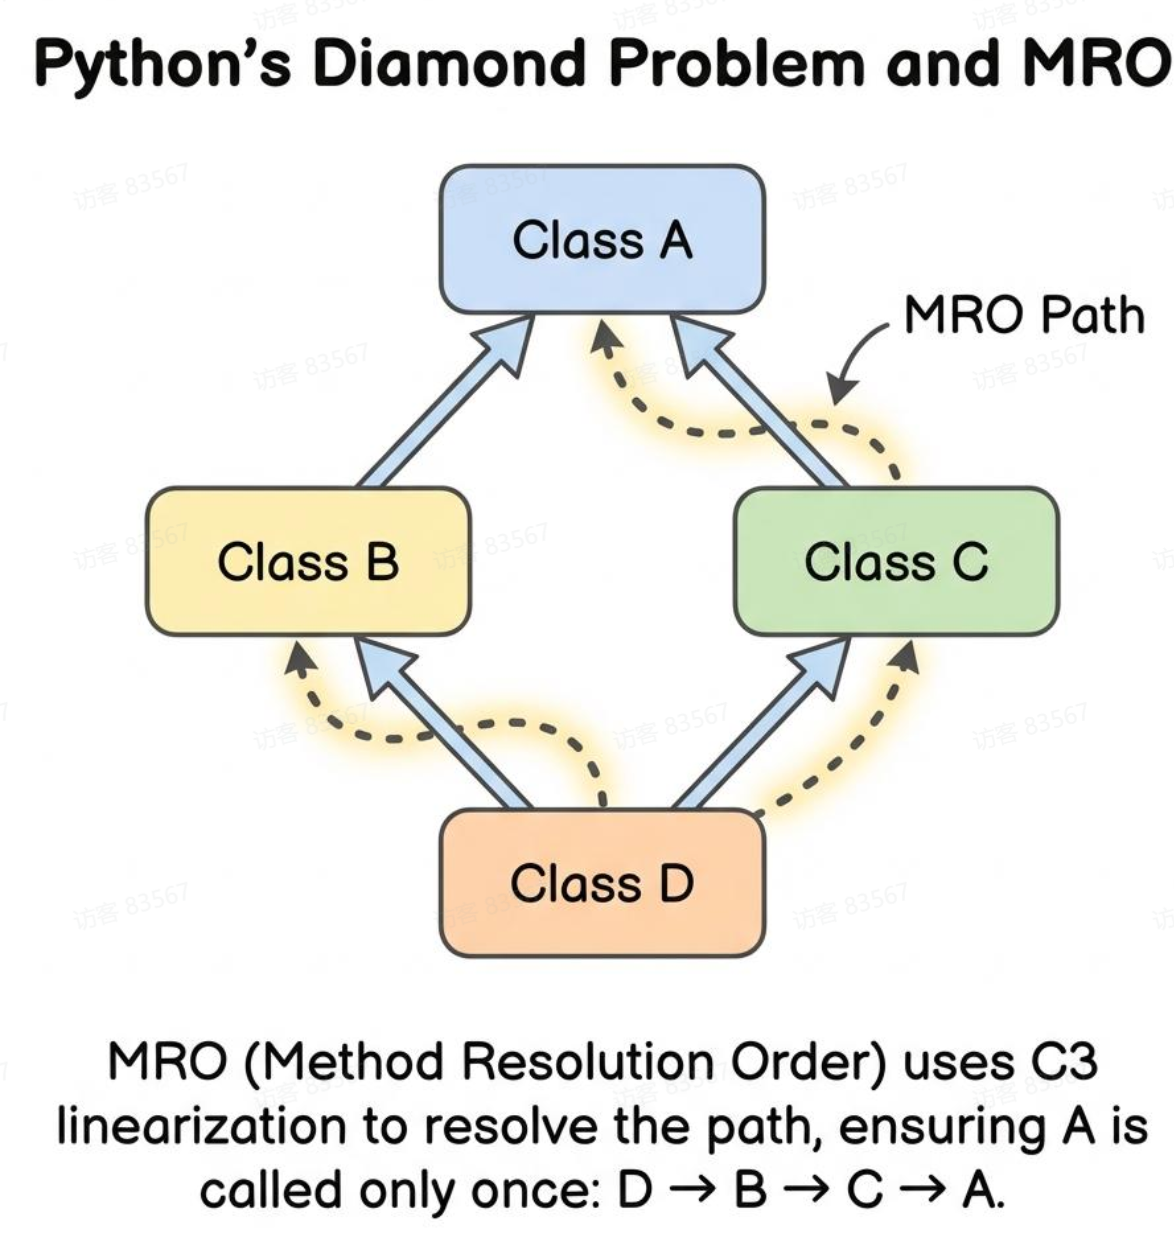

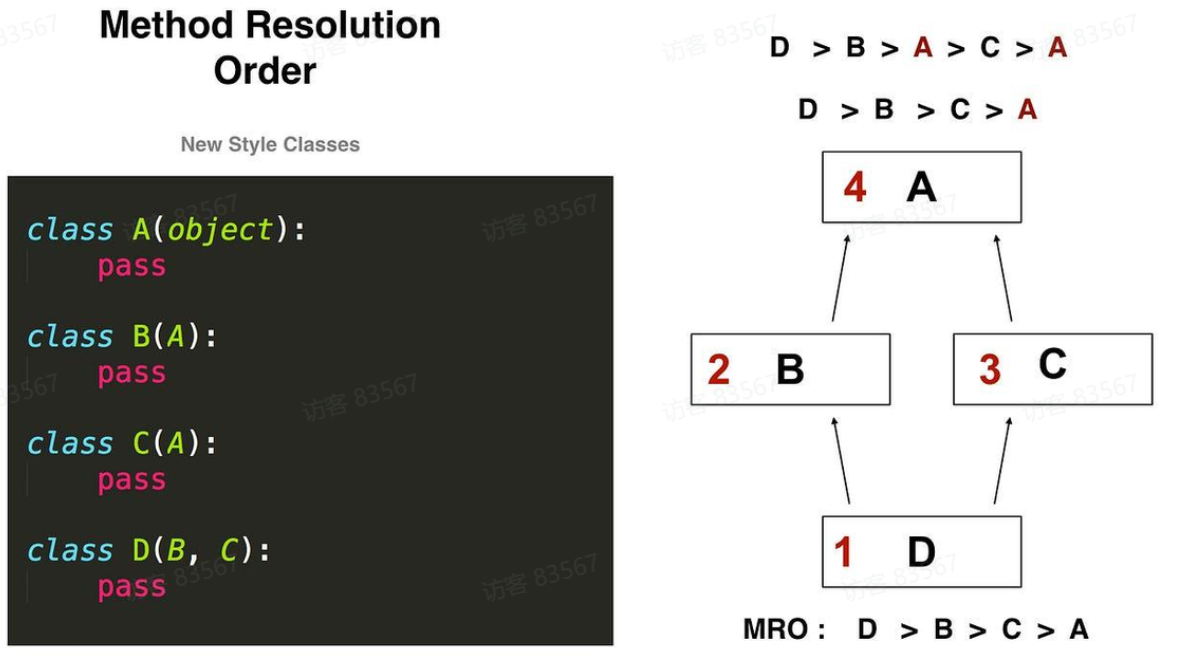

In [106]:
class A:
    def run(self):
        print("A")

class B(A):
    def run(self):
        print("B")
        super().run()

class C(A):
    def run(self):
        print("C")
        super().run()

class D(B, C):
    def run(self):
        print("D")
        super().run()

d = D()
d.run()

D
B
C
A


In [108]:
print(D.mro())
print(D.__mro__)

[<class '__main__.D'>, <class '__main__.B'>, <class '__main__.C'>, <class '__main__.A'>, <class 'object'>]
(<class '__main__.D'>, <class '__main__.B'>, <class '__main__.C'>, <class '__main__.A'>, <class 'object'>)
